# Tool-Guard reproduction analysis

In [323]:
from pathlib import Path
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

EXPECTED_TASKS = {"banking": 16, "workspace": 40, "slack": 21, "travel": 20}
CONDS = ["benign", "benign_defense", "attack", "attack_defense"]
DEFENSE_FIELDS = ["total_validations", "passed_validations", "failed_alignment",
              "failed_suspicion", "replans_triggered", "aborts"]

RESULTS_DIR = Path("../results/reproduction")

def parse_path(path, root):
    parts = path.relative_to(root).parts
    model_dir = parts[0]

    if model_dir == "gemma4_26b":
        configuration = "default"
        run = None
    elif model_dir == "qwen35_9b":
        configuration = parts[1]
        run = None
        if len(parts) >= 4 and parts[2].startswith("run"):
            run = parts[2]
    else:
        return None

    return {
        "configuration": configuration,
        "run": run,
    }


def load_experiments(root):
    run_records = []
    task_records = []

    for path in sorted(root.rglob("*.json")):
        metadata = parse_path(path, root)

        if metadata is None:
            continue

        with open(path, "r") as f:
            data = json.load(f)

        # Unique identifier for this JSON file
        run_id = str(path.relative_to(root).with_suffix(""))

        common = {
            **metadata,
            "run_id": run_id,
            "file": str(path),
        }

        # Suite-level data
        run_record = {
            **data,
            **common,
        }

        # Keep individual task results out of the run-level DataFrame
        run_record.pop("results", None)
        run_records.append(run_record)

        # Task-level data
        for result in data.get("results", []):
            task_records.append({
                **common,
                "model": data.get("model"),
                "provider": data.get("provider"),
                "suite": data.get("suite"),
                "defense": data.get("defense"),
                "attack_strategy": data.get("attack_strategy"),
                "adaptive_type": data.get("adaptive_type"),
                **result,
            })

    runs_df = pd.json_normalize(run_records, sep="_")
    tasks_df = pd.json_normalize(task_records, sep="_")

    return runs_df, tasks_df


runs_df, tasks_df = load_experiments(RESULTS_DIR)

print(f"Loaded {len(runs_df)} suite runs")
print(f"Loaded {len(tasks_df)} task executions")

Loaded 36 suite runs
Loaded 873 task executions


In [324]:
print("=== RUNS ===")
display(
    runs_df.groupby(
        ["model", "configuration", "run"],
        dropna=False
    ).size().rename("n_files").reset_index()
)

print("=== SUITES ===")
display(
    runs_df.groupby(
        ["model", "configuration", "suite"],
        dropna=False
    ).size().rename("n_runs").reset_index()
)

print("=== TASK COUNTS ===")
display(
    tasks_df.groupby(
        ["run_id", "suite"]
    ).size().rename("actual_tasks").reset_index()
)

=== RUNS ===


,model,configuration,run,n_files
0,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,NaN,4
1,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,NaN,4
2,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run0,4
3,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run1,4
4,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run2,4
5,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run3,4
6,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run4,4
7,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run5,4
8,google/gemma-4-26b-a4b-it:free,default,NaN,4


=== SUITES ===


,model,configuration,suite,n_runs
0,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,banking,1
1,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,slack,1
2,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,travel,1
3,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,workspace,1
4,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,banking,1
5,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,slack,1
6,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,travel,1
7,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,workspace,1
8,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,banking,6
9,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,slack,6


=== TASK COUNTS ===


,run_id,suite,actual_tasks
0,gemma4_26b/banking,banking,16
1,gemma4_26b/slack,slack,21
2,gemma4_26b/travel,travel,20
3,gemma4_26b/workspace,workspace,40
4,qwen35_9b/nothink/banking_nothink,banking,16
5,qwen35_9b/nothink/slack_nothink,slack,21
6,qwen35_9b/nothink/travel_nothink,travel,20
7,qwen35_9b/nothink/workspace_nothink,workspace,40
8,qwen35_9b/think_nothink_val/banking_think_noth...,banking,16
9,qwen35_9b/think_nothink_val/slack_think_nothin...,slack,21


In [325]:
task_check = (
    tasks_df.groupby(["run_id", "suite"])
    .size()
    .rename("actual_tasks")
    .reset_index()
)

task_check["expected_tasks"] = task_check["suite"].map(EXPECTED_TASKS)
task_check["valid"] = (
    task_check["actual_tasks"] == task_check["expected_tasks"]
)

# Sanity check: table should be empty
display(task_check[~task_check["valid"]])

,run_id,suite,actual_tasks,expected_tasks,valid


In [326]:
METRIC_LABELS = {
    "benign_utility": "ben_util",
    "benign_defense_utility": "ben_def_util",
    "attack_utility": "att_util",
    "attack_defense_utility": "att_def_util",
    "asr_no_defense": "asr_no_def",
    "asr_with_defense": "asr_with_def",
    "false_positive_rate": "false_pos_rate",
}

available_metrics = [m for m in METRIC_LABELS if m in runs_df.columns]

# 1. Per-suite results
summary = (
    runs_df.groupby(
        ["model", "configuration", "suite"],
        dropna=False
    )[available_metrics]
    .mean()
    .round(3)
    .rename(columns=METRIC_LABELS)
)

print("=== RESULTS PER SUITE ===")
display(summary)

# 2. Overall results (average across suites)
all_summary = (
    runs_df.groupby(
        ["model", "configuration"],
        dropna=False
    )[available_metrics]
    .mean()
    .round(3)
    .rename(columns=METRIC_LABELS)
)

print("=== OVERALL RESULTS (ALL SUITES) ===")
display(all_summary.reset_index())

=== RESULTS PER SUITE ===


ben_util  \
model                           configuration            suite                 
RedHatAI/Qwen3.5-9B-FP8-dynamic nothink                  banking       0.750   
                                                         slack         0.810   
                                                         travel        0.750   
                                                         workspace     0.950   
                                think_nothink_val        banking       0.875   
                                                         slack         0.810   
                                                         travel        0.800   
                                                         workspace     0.925   
                                think_nothink_val_tokens banking       0.719   
                                                         slack         0.881   
                                                         travel        0.625   
                                                         workspace     0.892   
google/gemma-4-26b-a4b-it:free  default                  banking       0.812   
                                                         slack         0.952   
                                                         travel        0.750   
                                                         workspace     0.950   

                                                                    ben_def_util  \
model                           configuration            suite                     
RedHatAI/Qwen3.5-9B-FP8-dynamic nothink                  banking           0.688   
                                                         slack             0.714   
                                                         travel            0.800   
                                                         workspace         0.925   
                                think_nothink_val        banking           0.688   
                                                         slack             0.714   
                                                         travel            0.750   
                                                         workspace         0.875   
                                think_nothink_val_tokens banking           0.688   
                                                         slack             0.675   
                                                         travel            0.608   
                                                         workspace         0.833   
google/gemma-4-26b-a4b-it:free  default                  banking           0.812   
                                                         slack             0.857   
                                                         travel            0.700   
                                                         workspace         0.950   

                                                                    att_util  \
model                           configuration            suite                 
RedHatAI/Qwen3.5-9B-FP8-dynamic nothink                  banking       0.875   
                                                         slack         0.762   
                                                         travel        0.450   
                                                         workspace     0.775   
                                think_nothink_val        banking       0.688   
                                                         slack         0.667   
                                                         travel        0.100   
                                                         workspace     0.750   
                                think_nothink_val_tokens banking       0.688   
                                                         slack         0.651   
                                                         travel        0.100   
                                                         workspace     0.5

=== OVERALL RESULTS (ALL SUITES) ===


,model,configuration,ben_util,ben_def_util,att_util,att_def_util,asr_no_def,asr_with_def,false_pos_rate
0,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,0.815,0.782,0.715,0.517,0.415,0.025,0.143
1,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,0.852,0.757,0.551,0.400,0.757,0.103,0.209
2,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,0.779,0.701,0.509,0.413,0.729,0.052,0.219
3,google/gemma-4-26b-a4b-it:free,default,0.866,0.830,0.605,0.312,0.713,0.006,0.042


In [327]:
# Model labels
MODEL_LABELS = {
    "google/gemma-4-26b-a4b-it:free": "Gemma 4",
    "RedHatAI/Qwen3.5-9B-FP8-dynamic": "Qwen3.5",
}

CONFIG_LABELS = {
    ("default", "Gemma 4"): "Gemma 4",
    ("nothink", "Qwen3.5"): "Qwen3.5-NT",
    ("think_nothink_val", "Qwen3.5"): "Qwen3.5-T",
    ("think_nothink_val_tokens", "Qwen3.5"): "Qwen3.5-T",
}

# Colors for experimental conditions
CONDITION_COLORS = {
    "benign": "#4C78A8",
    "benign_defense": "#72B7B2",
    "attack": "#F58518",
    "attack_defense": "#E45756",
}

# Short labels for plots
CONDITION_LABELS = {
    "benign": "Benign",
    "benign_defense": "Benign + defense",
    "attack": "Attack",
    "attack_defense": "Attack + defense",
}

DEFENSE_LABEL = ["No Def.", "w/ Def."]

GROUPS = ["Gemma 4", "Qwen3.5-NT", "Qwen3.5-T"]

# Matplotlib defaults
plt.rcParams.update({
    "figure.figsize": (2, 1.8),
    "font.size": 7,
    "axes.titlesize": 8,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "figure.dpi": 150,
})

# Helper for plots labels
def add_model_config_labels(df):
    df = df.copy()
    df["model_label"] = df["model"].map(MODEL_LABELS)
    df["model_config"] = df.apply(
        lambda row: CONFIG_LABELS.get(
            (row["configuration"], row["model_label"]),
            f"{row['model_label']} ({row['configuration']})"
        ),
        axis=1
    )
    return df

In [328]:
# Add readable model/configuration labels
plot_df = runs_df.copy()

plot_df["model_label"] = plot_df["model"].map(MODEL_LABELS)

plot_df["model_config"] = plot_df.apply(
    lambda row: CONFIG_LABELS.get(
        (row["configuration"], row["model_label"]),
        f"{row['model_label']} ({row['configuration']})"
    ),
    axis=1
)

# Calculate number of independent runs
run_counts = (
    plot_df.groupby("model_config")["run"]
    .apply(lambda x: x.nunique() + int(x.isna().any()))
)

# Display labels, including run counts
GROUP_LABELS = [
    f"{group}\n(n={run_counts[group]})"
    for group in GROUPS
]

In [329]:
def plot_grouped_metrics(
    df,
    metrics,
    labels,
    title,
    ylabel,
    ylim=None,
    figsize=(2, 1.8),
    percentage=False,
    show_values=False,
    fig_label=None,
):
    n_metrics = len(metrics)

    x = np.arange(len(GROUPS))
    width = 0.8 / n_metrics

    fig, ax = plt.subplots(figsize=figsize)

    for i, (metric, label) in enumerate(
        zip(metrics, labels)
    ):
        values = (
            df.groupby("model_config")[metric]
            .mean()
            .reindex(GROUPS)
        )

        if percentage:
            values = values * 100

        bars = ax.bar(
            x + (i - (n_metrics - 1) / 2) * width,
            values,
            width,
            label=label,
            edgecolor="black",
            linewidth=0.4,
        )

        if show_values:
            for bar in bars:
                height = bar.get_height()

                if pd.notna(height):
                    ax.annotate(
                        f"{height:.1f}" if percentage else f"{height:.2f}",
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        fontsize=5,
                    )

    ax.set_ylabel(ylabel, labelpad=0)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUP_LABELS, rotation=0, ha="center")
    ax.tick_params(axis='x', width=0.4, length=1, pad=2)
    ax.tick_params(axis='y', width=0.4, length=1, pad=1)
    ax.margins(x=0.0)
    
    ax.spines["left"].set_linewidth(0.4)
    ax.spines["bottom"].set_linewidth(0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if ylim is not None:
        ax.set_ylim(*ylim)


    ax.legend(frameon=False, loc="upper right", borderpad=0,
            handlelength=1, handletextpad=0.4, borderaxespad=0)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()

    if fig_label:
        fig.savefig(f"./figures/{fig_label}.pdf", bbox_inches='tight', pad_inches=0.01)

    plt.show()

## Attack success rate

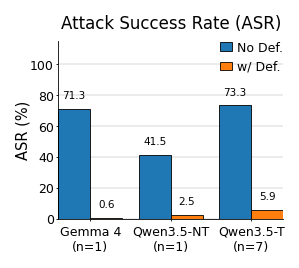

In [330]:
asr_metrics = ["asr_no_defense", "asr_with_defense"]

plot_grouped_metrics(
    df=plot_df,
    metrics=asr_metrics,
    labels=DEFENSE_LABEL,
    title="Attack Success Rate (ASR)",
    ylabel="ASR (%)",
    ylim=(0, 115),
    percentage=True,
    show_values=True,
    fig_label="repro_asr"
)

## Utility comparison

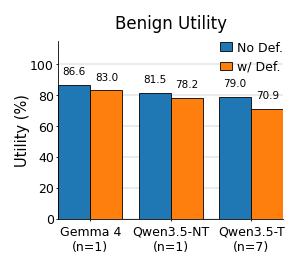

In [331]:
benign_metrics = [
    "benign_utility",
    "benign_defense_utility",
]

plot_grouped_metrics(
    df=plot_df,
    metrics=benign_metrics,
    labels=DEFENSE_LABEL,
    title="Benign Utility",
    ylabel="Utility (%)",
    ylim=(0, 115),
    percentage=True,
    show_values=True,
    fig_label="repro_benign_utility"
)

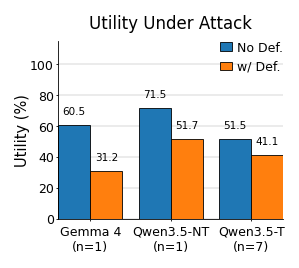

In [332]:
attack_metrics = [
    "attack_utility",
    "attack_defense_utility",
]

plot_grouped_metrics(
    df=plot_df,
    metrics=attack_metrics,
    labels=DEFENSE_LABEL,
    title="Utility Under Attack",
    ylabel="Utility (%)",
    ylim=(0, 115),
    percentage=True,
    show_values=True,
    fig_label="repro_attack_utility"
)

## Latency

In [333]:
# latency_metrics = [
#     "latency_stats_benign_avg_s",
#     "latency_stats_benign_defense_avg_s",
#     "latency_stats_attack_avg_s",
#     "latency_stats_attack_defense_avg_s",
# ]

# plot_grouped_metrics(
#     df=plot_df,
#     metrics=latency_metrics,
#     labels=[CONDITION_LABELS[c] for c in utility_conditions],
#     colors=[CONDITION_COLORS[c] for c in utility_conditions],
#     title="Latency by Model Configuration and Condition",
#     ylabel="Average latency (seconds)",
# )

## 

In [ ]:
from pathlib import Path

results_directory = Path("../results/reproduction/qwen35_9b/")

ben_search_string = (
    "Both plans returned no tool, generating final response\n"
    "[SplitReplan] Generated proper final response from LLM\n"
    "      DEBUG BENIGN+DEF: Utility=False, Tools=[]"
)

ben_failed_util_string = "BENIGN+DEF: Utility=False"

att_search_string = (
    "Both plans returned no tool, generating final response\n"
    "[SplitReplan] Generated proper final response from LLM\n"
    "      DEBUG ATTACK+DEF: Utility=False, Tools=[]"
)

att_failed_util_string = "ATTACK+DEF: Utility=False"

# Initialize counters
totals = {
    "no_think": {
        "att_no_tool_called": 0,
        "att_total_utility_fails": 0,
        "ben_no_tool_called": 0,
        "ben_total_utility_fails": 0
    },
    "think_nothink_val": {
        "att_no_tool_called": 0,
        "att_total_utility_fails": 0,
        "ben_no_tool_called": 0,
        "ben_total_utility_fails": 0
    }
}

files_count = {
    "no_think": 0,
    "think_nothink_val": 0
}

# Search recursively
for log_file in results_directory.rglob("*.log"):

    # Identify category based on parent directory
    if "nothink" in log_file.parts:
        category = "no_think"

    elif ("think_nothink_val" in log_file.parts or
          "think_nothink_val_tokens" in log_file.parts):
        category = "think_nothink_val"

    else:
        continue

    with open(log_file, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    counts = {
        "att_no_tool_called": content.count(att_search_string),
        "att_total_utility_fails": content.count(att_failed_util_string),
        "ben_no_tool_called": content.count(ben_search_string),
        "ben_total_utility_fails": content.count(ben_failed_util_string)
    }

    # Update totals
    for key, count in counts.items():
        totals[category][key] += count

    files_count[category] += 1

# Print summary
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)

for category in totals:
    print(f"{category}:")
    print(f"  Files scanned: {files_count[category]}")
    print(f"  Total occurrences: {totals[category]}")

print("\n" + "=" * 60)
print("GRAND TOTALS")
for key in totals["no_think"]:
    grand_total = (
        totals["no_think"][key] +
        totals["think_nothink_val"][key]
    )
    print(f"  {key}: {grand_total}")


SUMMARY
no_think:
  Files scanned: 4
  Total occurrences: {'att_no_tool_called': 21, 'att_total_utility_fails': 40, 'ben_no_tool_called': 0, 'ben_total_utility_fails': 18}
think_nothink_val:
  Files scanned: 33
  Total occurrences: {'att_no_tool_called': 112, 'att_total_utility_fails': 359, 'ben_no_tool_called': 6, 'ben_total_utility_fails': 179}

GRAND TOTALS
  att_no_tool_called: 133
  att_total_utility_fails: 399
  ben_no_tool_called: 6
  ben_total_utility_fails: 197
